In [25]:
# Real Estate Price Prediction Using Machine Learning Models

In [26]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
# Read the dataset
df = pd.read_excel('Real estate valuation data set.xlsx')
df

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...,...,...
409,410,2013.000000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,411,2012.666667,5.6,90.45606,9,24.97433,121.54310,50.0
411,412,2013.250000,18.8,390.96960,7,24.97923,121.53986,40.6
412,413,2013.000000,8.1,104.81010,5,24.96674,121.54067,52.5


In [28]:
#3 Data Exploration

In [29]:
df.shape

(414, 8)

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


In [31]:
df.describe()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148953,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281995,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.666667,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.916667,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.166667,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.416667,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583333,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


In [32]:
#4 Data Cleaning

In [33]:
df.isnull().sum()

No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

In [34]:
df.duplicated().sum()

0

In [35]:
df.shape

(414, 8)

In [36]:
df = df.drop(['No'], axis = 1)

In [37]:
df.isnull().sum()

X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

In [38]:
df.duplicated().sum()

0

In [39]:
df.shape

(414, 7)

The dataset has 414 rows and 8 columns then I removed the ID column because it is not useful for the model. We have no missing values or duplicates. Now the dataset has 414 rows and 7 columns.

In [41]:
#EDA

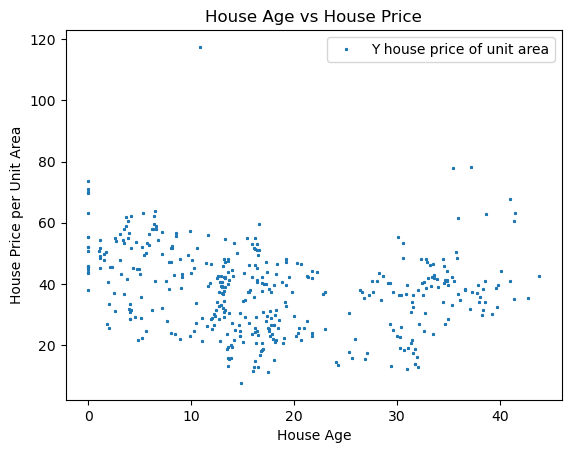

In [42]:
df.plot(x='X2 house age', y='Y house price of unit area', style='*', markersize=2)
plt.title('House Age vs House Price')
plt.xlabel('House Age')
plt.ylabel('House Price per Unit Area')
plt.show()

We see that new houses have higher prices most of the times. However, some old houses also have high prices. 
House age is not the only factor that affects the price. There are more factor that can determinate the price.

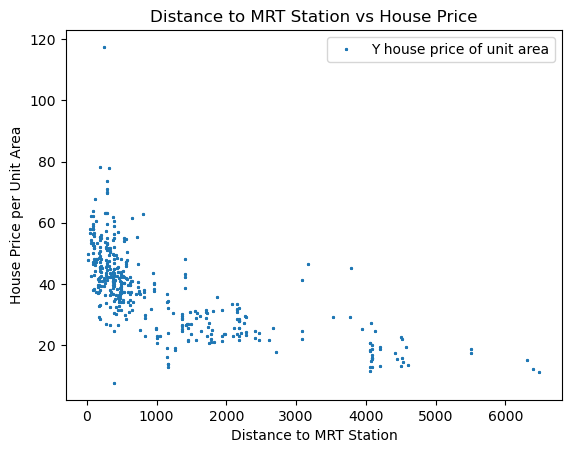

In [43]:
df.plot(x='X3 distance to the nearest MRT station', y='Y house price of unit area', style='*', markersize=2)
plt.title('Distance to MRT Station vs House Price')
plt.xlabel('Distance to MRT Station')
plt.ylabel('House Price per Unit Area')
plt.show()

Houses close to the MRT station they usually have higher prices but the ones far from the station have lower prices most of the times. Distance to public transport may be an important factor in the price, which makes sense

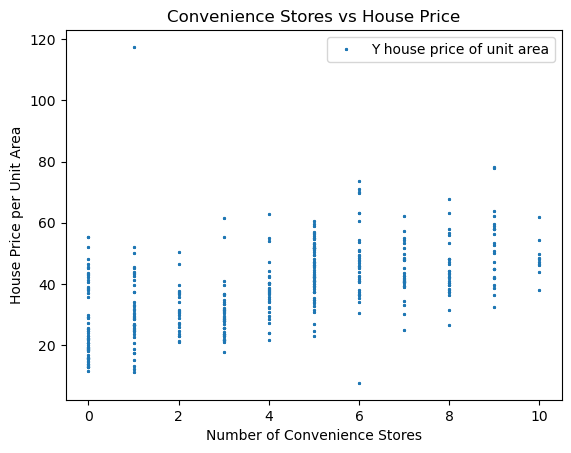

In [44]:
df.plot(x='X4 number of convenience stores', y='Y house price of unit area', style='*', markersize=2)
plt.title('Convenience Stores vs House Price')
plt.xlabel('Number of Convenience Stores')
plt.ylabel('House Price per Unit Area')
plt.show()

We can see here that the houses with more stores nearby usually have higher prices as well and the other hand the houses with fewer stores usually have lower prices. This kind of services also can determinate value

In [45]:
df.corr()

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
X1 transaction date,1.000000,0.017542,0.060880,0.009544,0.035016,-0.041065,0.087529
X2 house age,0.017542,1.000000,0.025622,0.049593,0.054420,-0.048520,-0.210567
X3 distance to the nearest MRT station,0.060880,0.025622,1.000000,-0.602519,-0.591067,-0.806317,-0.673613
X4 number of convenience stores,0.009544,0.049593,-0.602519,1.000000,0.444143,0.449099,0.571005
X5 latitude,0.035016,0.054420,-0.591067,0.444143,1.000000,0.412924,0.546307
X6 longitude,-0.041065,-0.048520,-0.806317,0.449099,0.412924,1.000000,0.523287
Y house price of unit area,0.087529,-0.210567,-0.673613,0.571005,0.546307,0.523287,1.000000


The distance to MRT station has the strongest correlation with the house prices -0.67, the convenience stores latitude and longitude have positive correlations. The house age and thetransaction date have weak correlations. We can see as well a strong negative correlation between longitude and distance to the MRT station of -0.81.

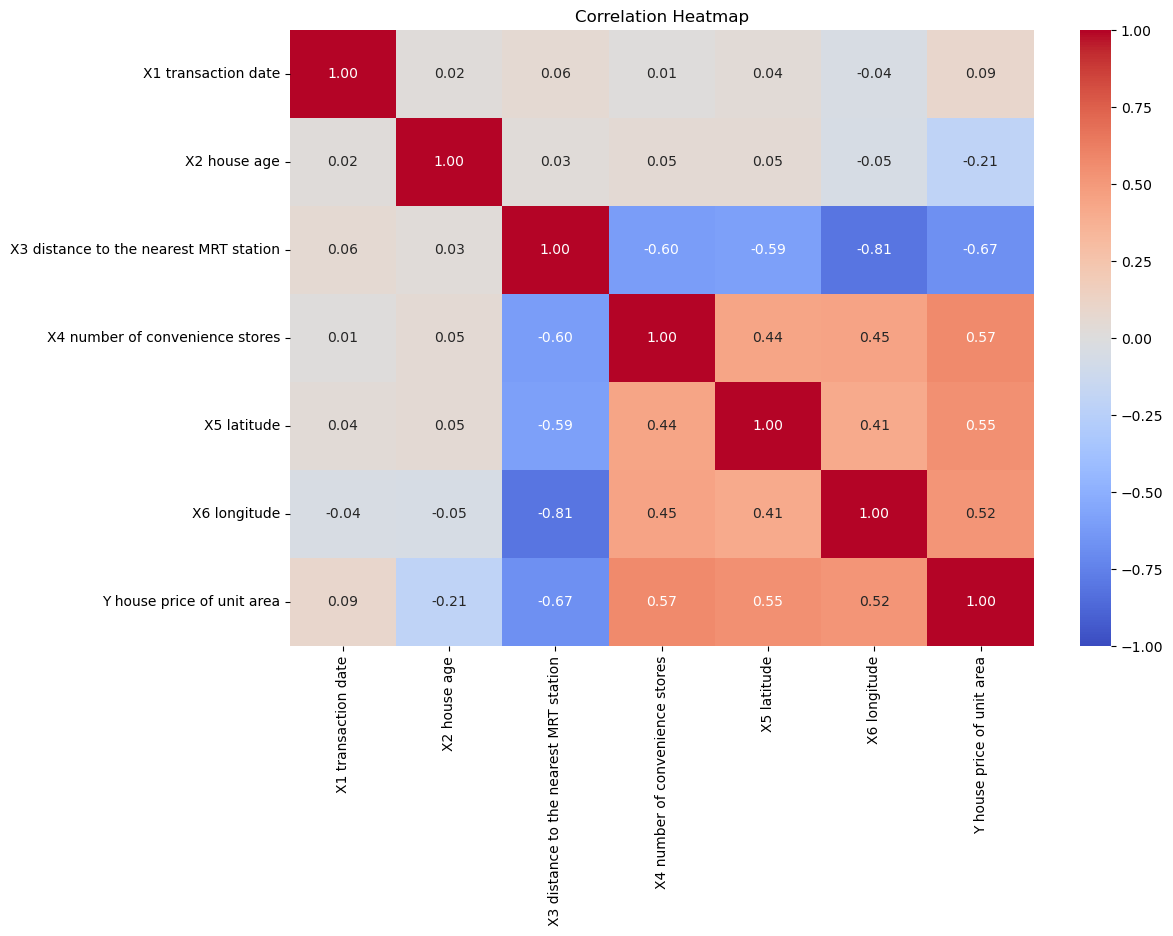

In [54]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)
plt.title('Correlation Heatmap')
plt.show()

We can see in the heatmap the positive and negative correlations:
The longitud and distance to the MRT station have a strong negative correlation -0.81.
I will keep all the six features to test them with different ml models.

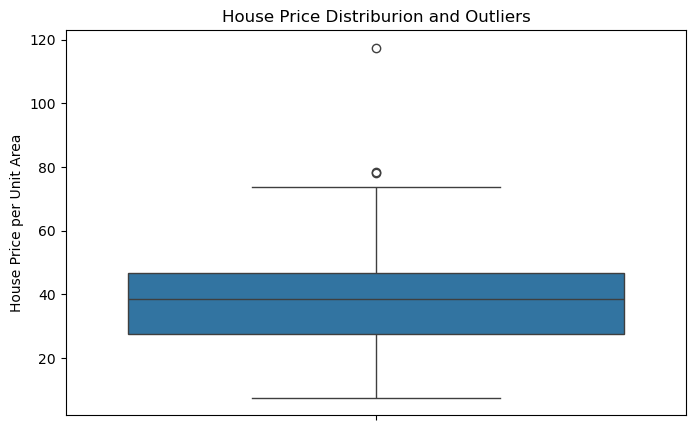

In [55]:
# Checking for possible outliers
plt.figure(figsize=(8, 5))
sns.boxplot(y='Y house price of unit area', data=df)
plt.title('House Price Distriburion and Outliers')
plt.ylabel('House Price per Unit Area')
plt.show()

In this boxplot we can see the price distribution.The median price is just below 40 and we can see outliers with very high prices. 

In [57]:
X =df.drop(columns=['Y house price of unit area'])
y =df['Y house price of unit area']

In [58]:
X.shape, y.shape

((414, 6), (414,))

In [60]:
#Defined independent and dependent variables
X = df.drop(columns=['Y house price of unit area'])
y = df['Y house price of unit area']

In [61]:
X.shape, y.shape

((414, 6), (414,))

In [62]:
import statsmodels.api as sm
X_const = sm.add_constant(X)

ols_model = sm.OLS(y, X_const).fit()

print(ols_model.pvalues)

const                                     3.364344e-02
X1 transaction date                       1.025782e-03
X2 house age                              1.063915e-11
X3 distance to the nearest MRT station    1.037344e-09
X4 number of convenience stores           3.826895e-09
X5 latitude                               6.382166e-07
X6 longitude                              7.982028e-01
dtype: float64


We can see that five of the six features have a p-value under 0.05. Longitud have a high p-value of 0.7982 which is not statistically too significant in this model

In [66]:
from sklearn.model_selection import train_test_split
#Split dataset - 95% training and 5% in testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.05, random_state=42)

In [65]:
X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape

((414, 6), (414,), (393, 6), (21, 6), (393,), (21,))

In [67]:
from sklearn.linear_model import LinearRegression

#LR model
lr_model = LinearRegression()
#Train model
lr_model.fit(X_train, y_train)

LinearRegression()

In [69]:
#Predict house prices with the test data
y_pred_lr = lr_model.predict(X_test)

In [70]:
print(lr_model.intercept_)
print(lr_model.coef_)

-13932.17792134183
[ 5.41184270e+00 -2.70564395e-01 -4.69008870e-03  1.10339466e+00
  2.11933273e+02 -1.81937824e+01]


In [71]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("MAE:", mae_lr)
print("MSE:", mse_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)

MAE: 6.13856980826623
MSE: 71.55675772995798
RMSE: 8.45912275179631
R2 Score: 0.6476484967707445


The Linear Regression model has an R2 score of 0.647 and the MAE is 6.185 and the RMSE is 8.459. In this case the model explain about 65% of the price variation in the test data. Lets test the other models to see which one works better.

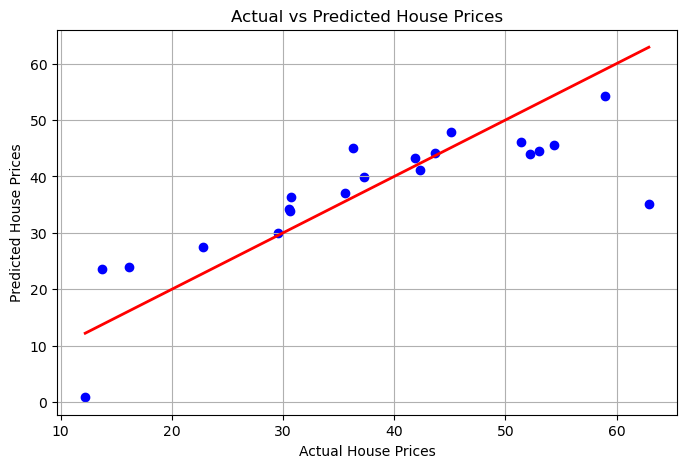

In [72]:
# lets plot the actual vs the predicted house prices:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_lr, color='blue')
plt.plot([min(y_test), max(y_test)],
         [min(y_test), max(y_test)],
         color='red', lw=2)

plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.grid(True)
plt.show()

Not very accurate

In [91]:
from sklearn.model_selection import cross_val_score
cv_scores_lr = cross_val_score(lr_model, X_train, y_train, cv=10, scoring='r2')
mean_cv_score_lr = np.mean(cv_scores_lr)

print(f"Mean CrossValidation Score(R2): {mean_cv_score_lr:.4f}")

Mean CrossValidation Score(R2): 0.5644


Cross-Validation score is 0.5644, which is lower than the test score of aprox 0.65

In [77]:
from sklearn.tree import DecisionTreeRegressor
#Decision Tree model
dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [78]:
y_pred_dt = dt_model.predict(X_test)
#price prediction

In [79]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("MAE:", mae_dt)
print("MSE:", mse_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)

MAE: 4.709523809523809
MSE: 55.64999999999999
RMSE: 7.459892760623305
R2 Score: 0.7259747118684946


The Decision Tree model has an r2 score of 0.725, the MAE is around 4.71 and the RMSE is 7.45. The Decision Tree has a higher r2 score and lower errors than LR. 

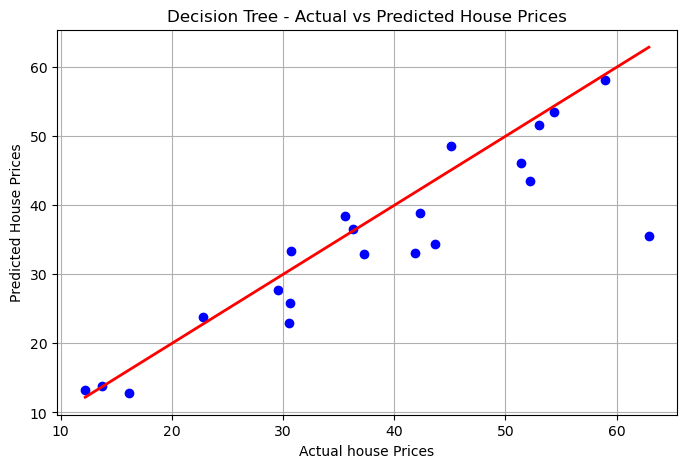

In [80]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_dt, color='blue')
plt.plot([min(y_test), max(y_test)],
         [min(y_test), max(y_test)],
         color='red', lw=2)

plt.title('Decision Tree - Actual vs Predicted House Prices')
plt.xlabel('Actual house Prices')
plt.ylabel('Predicted House Prices')
plt.grid(True)
plt.show()

In [90]:
cv_scores_dt = cross_val_score(dt_model, X_train, y_train, cv=10, scoring='r2')
#Calculate average score
mean_cv_score_dt = np.mean(cv_scores_dt)
print(f"Mean CrossValidation Score (R2): {mean_cv_score_dt:.4f}")

Mean CrossValidation Score (R2): 0.4606


Some of the blue points are closeer to the red line here the model predicts some of the house prices well but some points are far from the line, especially when we look at the expensive houses. The model still has errors.
The Decision Tree has a CrossValidation R2 score of 0.46, which is lower than its test score of 0.73. The Linear Regression has a better CrossValidation score. 

In [82]:
from sklearn.ensemble import RandomForestRegressor
#Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [83]:
#Predict prices
y_pred_rf = rf_model.predict(X_test)

In [84]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

MAE: 4.765460317460319
MSE: 56.4124474597619
RMSE: 7.510822022905476
R2 Score: 0.7222203563456484


The random forest model has an R2 score of 0.72, the MAE is 4.77 and the RMSE is 7.51. The results are very similar to the Decision Tree results and both models have a better test results than linear regression model

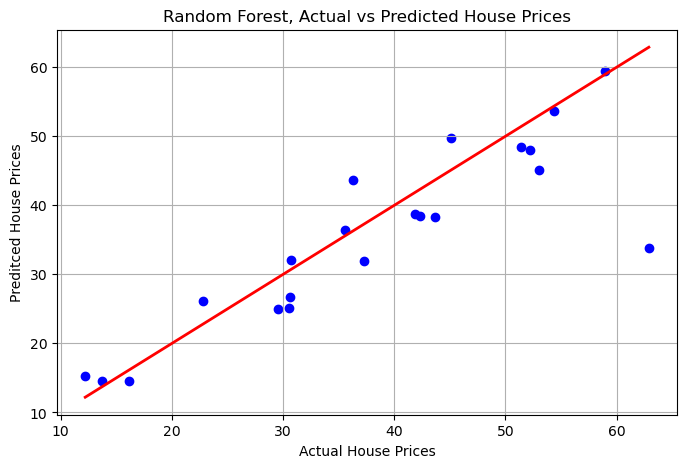

In [85]:
#Actual vs predicted house prices
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_rf, color='blue')
plt.plot([min(y_test), max(y_test)],
         [min(y_test), max(y_test)],
         color='red', lw=2)

plt.title('Random Forest, Actual vs Predicted House Prices')
plt.xlabel('Actual House Prices')
plt.ylabel('Preditced House Prices')
plt.grid(True)
plt.show()

In [88]:
# crossvalidation
cv_scores_rf = cross_val_score(rf_model, X_train, y_train, cv=10, scoring='r2')
mean_cv_score_rf = np.mean(cv_scores_rf)

print(f"Mean CrossValidation Score (R2): {mean_cv_score_rf:.4f}")

Mean CrossValidation Score (R2): 0.6894


In [94]:
feature_imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
feature_imp

X3 distance to the nearest MRT station    0.586933
X2 house age                              0.180907
X6 longitude                              0.085187
X5 latitude                               0.083540
X1 transaction date                       0.042517
X4 number of convenience stores           0.020916
dtype: float64

Many of the blue points are close to the red line in this case the model predicts low and medium house prices quite well. We still see some expensive houses have lower predicted prices than their actual prices
The random forest has a CrossValidation R2 score of 0.689, this is better than the linear regression and decision tree and also, the test and CrossValidation scores are also very close

Distance to the MRT station is the most important feature with 58.69%. As second, house age is an important feature, with 18.09%. And the number of convenience stores is the least important in this model.